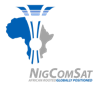 &nbsp;&nbsp; 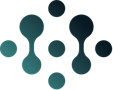

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Publica-AI/nigcomsat-ai-developer/blob/jasons-restructure/Jasons-Restructure/week-5/day-3-regression-forecasts-and-intervals/2-exercise/W5D3-exercise.ipynb)

# 🌉 Week 5 · Day 3: Regression Forecasts + Honest Ranges

**Today:** you build the code book's regression forecast without leaking the future, score it like with like, and fence it with a 90% band that you **check**. Then you build your Checkpoint 4 table.

| Symbol | Means |
|---|---|
| 📖 | Read this |
| ▶️ | Run the cell below (click it, then **Shift + Enter**) |
| ✍️ | Your turn: replace every `___` with your answer |
| ✅ / ❌ | The check tells you if you got it right, with a hint if not |
| 🌶️ | Bonus task for fast finishers |

> ## ⚠️ Do this FIRST: **File → Save a copy in Drive**

**Rule book:** keep `W5D3-rulebook.pdf` open next to you.

## ▶️ STEP 0: Set up
Run it once every time you open the notebook (and after every restart). Wait for `✅ Ready!`.

In [ ]:
#@title 🚀 STEP 0 · Run me first (click the ▶ button on the left of this cell) { display-mode: "form" }
import sys, warnings
warnings.filterwarnings("ignore")
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from pathlib import Path
from urllib.request import urlretrieve

pd.set_option("display.width", 130)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (11, 3.6), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "axes.titleweight": "bold",
                     "axes.prop_cycle": plt.cycler(color=["#0A5DB4", "#C77700", "#008C7E"])})

IN_COLAB = "google.colab" in sys.modules
RAW = "https://raw.githubusercontent.com/Publica-AI/nigcomsat-ai-developer/main/Time-series"
DATA_HOME = {'additive_multiplicative_demo': 'week-03', 'bandwidth_throughput_daily': 'week-03', 'ka_band_availability_daily': 'week-03', 'ka_band_availability_monthly': 'week-03', 'link_margin_hourly_aug2025': 'week-03', 'noc_tickets_daily': 'week-03', 'noc_tickets_weekly': 'week-03', 'transponder_utilisation_monthly': 'week-03', 'vsat_uptime_by_region_weekly': 'week-03', 'rf_link_quality_hourly': 'week-03', 'bus_power_telemetry_hourly': 'week-04', 'battery_health_daily': 'week-04', 'twta_thermal_daily': 'week-04', 'telemetry_anomaly_labels': 'week-04', 'bus_telemetry_multivariate_hourly': 'week-05', 'anomaly_labels_week5': 'week-05', 'degradation_assets_daily': 'week-06', 'degradation_thresholds': 'week-06', 'ops_tickets_weekly': 'week-06'}

def data_path(name, week=None):
    """Download a course CSV once and return where it is saved.
    week: which original folder to use, e.g. "week-03" (two files exist in both week-03 and week-04).
    If you uploaded the file yourself (Files panel), that copy is used instead."""
    uploaded = Path(f"{name}.csv")
    if uploaded.exists():
        return uploaded
    week = week or DATA_HOME[name]
    local = Path("course_data") / week / f"{name}.csv"
    if not local.exists():
        local.parent.mkdir(parents=True, exist_ok=True)
        urlretrieve(f"{RAW}/{week}/data/{name}.csv", local)
    return local

def load_labels(name="telemetry_anomaly_labels", week=None):
    """Read an answer-key (labels) file. The original telemetry_anomaly_labels.csv has a stray comma
    inside one description, which makes pd.read_csv crash, so the last column is read as free text."""
    lines = Path(data_path(name, week)).read_text(encoding="utf-8").splitlines()
    cols = lines[0].split(",")
    rows = [ln.split(",", len(cols) - 1) for ln in lines[1:] if ln.strip()]
    df = pd.DataFrame(rows, columns=cols)
    for c in ("start", "end"):
        if c in df:
            df[c] = pd.to_datetime(df[c], format="mixed")
    return df

___ = None          # this is "the blank". Replace every ___ with your answer.
SCORE = {}

def _blank(x):
    return x is None or (isinstance(x, tuple) and any(v is None for v in x))

def check(task, answer):
    """Marks one task. Prints ✅ or ❌ with a hint."""
    if _blank(answer):
        print("✍️  Fill in the blank first: replace ___ with your answer, then run the cell again.")
        return
    try:
        ok, good, hint = CHECKS[task](answer)
    except Exception as e:
        ok, good, hint = False, "", f"{HINTS.get(task, 'Read the task again.')}  (Python said: {type(e).__name__})"
    SCORE[task] = ok
    print(("✅ " + good) if ok else ("❌ Not yet. Hint: " + hint))

def scoreboard():
    got = sum(SCORE.values())
    print(f"You have {got} of {len(CHECKS)} tasks correct.")
    print("🏆 Oya, you don finish! Mad o!" if got == len(CHECKS) else "💪 Keep going: scroll up and fix the ❌ ones.")

# ---- today's checks ----
def _near(x, want, tol):
    return abs(float(x) - want) <= tol

def _c_a1(x):
    v = int(x)
    hint = ("shift(-1) copies NEXT week's count back: tomorrow's newspaper. You need the past: a positive number."
            if v < 0 else "Last week is ONE week back.")
    return v == 1, "shift(1) puts LAST week's count on this week's row: 74 on 3 Nov. You knew it on Monday morning. 🔒", hint

def _c_a2(x):
    return int(x) == 52, "52 rows: shift(52) has nothing to copy in the first year, so dropna() drops all of 2024.", \
        "Count the rows that disappeared: len(tickets) - len(feat)"

def _c_a3(x):
    return tuple(int(v) for v in x) == (44, 8), \
        "44 training weeks, 8 test weeks, and the assert passed: training ends before the test begins. ✂️", \
        "Hold out the last 8 weeks, like last time: H = 8"

def _c_b1(x):
    return _near(x, 5.85081762463898, 0.01), f"MAE {float(x):.2f}: half of naive's 11.25! 🎉 …hold the applause until B3.", \
        "The column the model learns to reproduce is called \"target\" (in quotes)."

def _c_b2(x):
    v = float(x)
    return _near(v, np.float64(0.02310105335218603), 1e-4) and v > 0, \
        "+23 tickets a week per 1,000 extra terminals. Bigger network, more tickets: the sign makes sense ✅. A negative sign would be a warning.", \
        "Read it from the Series: coefs[\"terminals\"]"

def _c_b3(x):
    return _near(x, 6.75, 0.01), f"{float(x):.2f}: naive with the same hint (last week's real count). The regression's real edge is under 1 ticket. ⚖️", \
        "One-step naive = last week's REAL count, which is the column \"tickets_lag1\"."

def _c_b4(x):
    return x is False, "Right: even with a hint every week, the regression loses to the rate seasonal naive (2.24), forecast 8 weeks blind. 🏆👵🏾", \
        "Look at the table: which MAE is smallest? Answer True or False (no quotes)."

def _c_c1(x):
    z, cov = x
    return _near(z, 1.645, 0.0011) and int(cov) == 5, \
        "± 4.67 covers only 5 of 8 weeks. A “90%” band that's right 5 times in 8: too narrow. 😬", \
        "The 90% two-sided normal number: 1.645"

def _c_c2(x):
    half, cov = x
    return _near(half, 8.1996377455998, 0.01) and int(cov) == 7, \
        "± 8.20 covers 7 of 8: a band you can quote. Same forecast, only the width changed. ✅", \
        "90th percentile, written as a fraction: Q = 0.9"

def _c_c3(x):
    half, cov = x
    return _near(half, 3.329818502157407, 0.01) and int(cov) == 2, \
        "Summer-only misses → ± 3.33 → 2 of 8. A band is only as honest as the weeks you measured it on. 🌧️", \
        "Type the date as text: \"2025-05-19\""

def _c_c4(x):
    half, cov = x
    return _near(half, 7.009652671901705, 0.01) and int(cov) == 8, \
        "± 7.01 and 8 of 8 inside: the best forecast, with an honest band. 🏆", \
        "The first test week sits at position len(tickets) - H"

def _c_c5(x):
    return x is False, "False. Raising z until the test looks right is tuning on the answers: expo again. The width must come from misses BEFORE the test.", \
        "Is choosing z by looking at the test weeks honest? True or False (no quotes)."

def _c_d1(x):
    return "rate" in str(x).lower(), "The rate seasonal naive: lowest MAE, 8 weeks ahead without peeking, and an honest band that covered 8 of 8. Recommend the simpler model. ⚖️", \
        "Lowest MAE with an honest, checked band. Type its name in quotes."

def _c_bonus(x):
    lo, hi = x
    return _near(lo, np.float64(49.35180828527714), 1.0) and _near(hi, np.float64(63.37111362908055), 1.0), \
        "“Week of 3 Nov: most likely around 56, plausibly 49 to 63; expect bigger misses at season changes.” That's Amaka. 🌉", \
        "rate_fc[0] - half_rate and rate_fc[0] + half_rate, as a pair (low, high)"

CHECKS = {"A1": _c_a1, "A2": _c_a2, "A3": _c_a3, "B1": _c_b1, "B2": _c_b2, "B3": _c_b3, "B4": _c_b4,
          "C1": _c_c1, "C2": _c_c2, "C3": _c_c3, "C4": _c_c4, "C5": _c_c5, "D1": _c_d1, "BONUS": _c_bonus}
HINTS = {"A1": "LAG is a whole number.", "A3": "H is a number of weeks.", "C2": "Q is a fraction between 0 and 1.",
         "C3": "SUMMER_START is a date in quotes, like \"2025-05-19\".", "C4": "ORIGIN is a whole number: len(tickets) - H",
         "BONUS": "Give a pair: (low, high)."}

print(f"✅ Ready! pandas {pd.__version__} · running in {'Google Colab' if IN_COLAB else 'Jupyter'}. Scroll down and let's go 🚀")


### ▶️ The data
Two years of weekly NOC tickets and the network size, the same file as last time.

In [ ]:
from sklearn.linear_model import LinearRegression

tickets = pd.read_csv(data_path("ops_tickets_weekly"), parse_dates=["week_start"], index_col="week_start").asfreq("W-MON")
print("weeks:", len(tickets), "· gaps:", int(tickets.isna().sum().sum()), "·", tickets.index[0].date(), "to", tickets.index[-1].date())
tickets.tail(3)

### ▶️ 🧰 Your toolbox (run it once)
The baselines from last time (`naive`, `seasonal_naive`, `rate_seasonal_naive`, `mae` …), the code book's feature builder `make_features`, and two helpers for honest past misses. Read them once, then run.

In [ ]:
def naive(series, h):
    """Grandma's forecast: the last value we saw, repeated h times."""
    return np.full(h, float(series.iloc[-1]))

def seasonal_naive(series, h, period=52):
    """The same weeks one season (52 weeks) ago."""
    last_season = series.iloc[-period:].values
    return np.tile(last_season, int(np.ceil(h / period)))[:h].astype(float)

def moving_average(series, h, window=8):
    """The mean of the last `window` weeks, held flat."""
    return np.full(h, float(series.iloc[-window:].mean()))

def exp_smoothing(series, h, alpha=0.3):
    """Simple exponential smoothing: a running level, each new week pulls it alpha of the way."""
    level = series.iloc[0]
    for v in series.iloc[1:]:
        level = alpha * v + (1 - alpha) * level
    return np.full(h, float(level))

def rate_seasonal_naive(series, terminals, h, period=52):
    """Grandma, adjusted for the bigger family: last year's tickets PER TERMINAL x today's terminals."""
    rate = series / terminals
    return rate.iloc[-period:].values[:h] * float(terminals.iloc[-1])

def mae(forecast, actual):
    """Mean absolute error: on a typical week, how many tickets were we off by?"""
    return float(np.mean(np.abs(np.asarray(forecast, float) - np.asarray(actual, float))))

def make_features(df):
    """The code book's feature table. Every column is known BEFORE the week starts."""
    f = pd.DataFrame(index=df.index)
    f["tickets_lag1"] = df["tickets_raised"].shift(1)     # last week (shift(+1) = the past)
    f["tickets_lag52"] = df["tickets_raised"].shift(52)   # same week, last year
    f["terminals"] = df["active_vsat_terminals"]
    woy = df.index.isocalendar().week.astype(int)
    f["sin52"] = np.sin(2 * np.pi * woy / 52)             # week of year as a smooth circle
    f["cos52"] = np.cos(2 * np.pi * woy / 52)
    f["target"] = df["tickets_raised"]
    return f.dropna()

def walk_forward_errors(feat, x_cols, first=12):
    """Honest past misses: for each week from row `first`, fit on the rows BEFORE it, forecast it, keep the miss."""
    errors = []
    for k in range(first, len(feat)):
        model = LinearRegression().fit(feat[x_cols].iloc[:k], feat["target"].iloc[:k])
        errors.append(feat["target"].iloc[k] - model.predict(feat[x_cols].iloc[[k]])[0])
    return np.array(errors)

def rate_past_errors(df, origin, h=8, period=52):
    """Misses of every h-week rate forecast made from an earlier origin whose h weeks end before `origin`."""
    errors = []
    for o in range(period, origin - h + 1):
        f = rate_seasonal_naive(df["tickets_raised"].iloc[:o], df["active_vsat_terminals"].iloc[:o], h, period)
        errors.extend(df["tickets_raised"].iloc[o:o + h].values - f)
    return np.array(errors)

def coverage(forecast, half, actual):
    """How many weeks fall inside forecast ± half."""
    actual = np.asarray(actual, float)
    return int(((actual >= forecast - half) & (actual <= forecast + half)).sum())

print("✅ toolbox ready: naive, seasonal_naive, rate_seasonal_naive, mae, make_features, walk_forward_errors, rate_past_errors, coverage")

---
# Part A: Features without a leak (12 min) 🔒

📖 **The leak rule:** every feature must be known **before the week starts**. On Monday morning you know last week's tickets, not this week's and certainly not next week's.

### A1 ✍️ Last week's count
`shift(LAG)` moves the column down by `LAG` rows. Which `LAG` puts **last week's** count on this week's row? Look at the table it prints around 3 November.

In [ ]:
LAG = ___

assert LAG is not None, "✍️ Fill in LAG first."
peek = pd.DataFrame({"tickets": tickets["tickets_raised"], f"shift({LAG})": tickets["tickets_raised"].shift(LAG)})
display(peek.loc["2025-10-20":"2025-11-17"])
check("A1", LAG)

### A2 ✍️ The feature table
▶️ `make_features` builds the code book's five columns plus the `target`. ✍️ How many rows did it lose? (Compare its length with `tickets`.)

In [ ]:
feat = make_features(tickets)
print("feature table:", feat.shape)
display(feat.head(3).round(3))

rows_lost = ___

check("A2", rows_lost)

### A3 ✍️ The split by time
Hold out the **last 8 weeks** (3 Nov – 22 Dec 2025), exactly as last time. Training = every row **before** them.

In [ ]:
H = ___

assert H is not None, "✍️ Fill in H first."
CUT = feat.index[-H]
train_f = feat.loc[:CUT].iloc[:-1]      # strictly before the test weeks
test_f = feat.loc[CUT:]
assert train_f.index.max() < test_f.index.min(), "leakage: training overlaps the test"
print("train:", len(train_f), "weeks,", train_f.index[0].date(), "to", train_f.index[-1].date())
print("test: ", len(test_f), "weeks,", test_f.index[0].date(), "to", test_f.index[-1].date())
check("A3", (len(train_f), len(test_f)))

---
# Part B: The regression, scored like with like (15 min) 📈

### B1 ✍️ Fit and score
`LinearRegression` finds the weights that make *weight × column + weight × column + …* closest to the target on the training weeks. Which column is the target?

In [ ]:
assert "train_f" in globals(), "✍️ Finish A3 first."
X_COLS = ["tickets_lag1", "tickets_lag52", "terminals", "sin52", "cos52"]

TARGET = ___

assert TARGET is not None, "✍️ Fill in TARGET first."
reg = LinearRegression().fit(train_f[X_COLS], train_f[TARGET])
pred = reg.predict(test_f[X_COLS])
reg_mae = mae(pred, test_f["target"])
print(f"regression MAE on the 8 held-out weeks: {reg_mae:.2f} tickets/week")
check("B1", reg_mae)

### B2 ✍️ Read the signs like an engineer
A coefficient says how much the forecast moves for one more unit of that column. More terminals should mean more tickets. Pull out the `terminals` coefficient.

In [ ]:
assert "reg" in globals(), "✍️ Finish B1 first."
coefs = pd.Series(reg.coef_, index=X_COLS)
print(coefs.round(4))

terminals_coef = ___

check("B2", terminals_coef)

### B3 ✍️ Like with like
📖 The regression was handed **last week's real count** (`tickets_lag1`) for every test week: it's a **one-week-ahead** forecast. Last time's naive forecast all 8 weeks blind. Make naive the same way: "this week = last week's real count". Which column holds that?

In [ ]:
assert "test_f" in globals(), "✍️ Finish A3 first."

NAIVE_COL = ___

assert NAIVE_COL is not None, "✍️ Fill in NAIVE_COL first."
onestep_naive_mae = mae(test_f[NAIVE_COL], test_f["target"])
print(f"one-step naive MAE: {onestep_naive_mae:.2f}")
check("B3", onestep_naive_mae)

▶️ Every method on the same 8 weeks, with how far ahead it forecast and what it knew.

In [ ]:
assert "onestep_naive_mae" in globals() and "reg_mae" in globals(), "✍️ Finish B1 and B3 first."
train_y = tickets["tickets_raised"].iloc[:-H]
train_t = tickets["active_vsat_terminals"].iloc[:-H]
actual = tickets["tickets_raised"].iloc[-H:]
like = pd.DataFrame([
    {"method": "naive (W5D2)", "how far ahead": "8 weeks, blind", "MAE": mae(naive(train_y, H), actual)},
    {"method": "seasonal naive (W5D2)", "how far ahead": "8 weeks, blind", "MAE": mae(seasonal_naive(train_y, H), actual)},
    {"method": "rate seasonal naive (W5D2)", "how far ahead": "8 weeks, blind", "MAE": mae(rate_seasonal_naive(train_y, train_t, H), actual)},
    {"method": "one-step naive", "how far ahead": "1 week", "MAE": onestep_naive_mae},
    {"method": "regression", "how far ahead": "1 week", "MAE": reg_mae},
]).set_index("method").round(2)
like

### B4 ✍️ Did the regression beat the best baseline?
Answer `True` or `False` (no quotes).

In [ ]:
regression_beats_best_baseline = ___

check("B4", regression_beats_best_baseline)

---
# Part C: Honest ranges (18 min) ↔️

### C1 ✍️ The code book's 90% band
Band = forecast ± **z** × (the spread of the training misses). For a two-sided 90% band on a bell curve, z = **1.645**. `coverage()` counts how many of the 8 real weeks land inside.

In [ ]:
assert "pred" in globals(), "✍️ Finish B1 first."
resid = train_f["target"] - reg.predict(train_f[X_COLS])
resid_sd = resid.std()
print(f"training residual sd: {resid_sd:.2f}")

Z = ___

assert Z is not None, "✍️ Fill in Z first."
half_insample = Z * resid_sd
covered_insample = coverage(pred, half_insample, test_f["target"])
print(f"band: forecast ± {half_insample:.2f} → covers {covered_insample} of {len(test_f)} held-out weeks")
check("C1", (Z, covered_insample))

▶️ Why so narrow? Look at the misses on the weeks it never saw, especially **3 November**, the week the rains end.

In [ ]:
assert "pred" in globals(), "✍️ Finish B1 first."
misses = pd.DataFrame({"last week (lag1)": test_f["tickets_lag1"], "forecast": pred,
                       "actual": test_f["target"], "miss": test_f["target"] - pred}).round(1)
display(misses)
print(f"spread of the training misses: {resid_sd:.2f} · spread of the held-out misses: {misses['miss'].std():.2f}")

### C2 ✍️ An honest band: misses made before it knew the answer
📖 `walk_forward_errors` walks through the training weeks from row 12 (24 Mar): fit on the weeks **before**, forecast the next week, write down the miss. Then: band = forecast ± the **90th-percentile** miss.
Write 90th percentile as a fraction for `Q`.

In [ ]:
assert "pred" in globals(), "✍️ Finish B1 first."
past_misses = walk_forward_errors(train_f, X_COLS, first=12)
print(len(past_misses), "honest past misses, from", train_f.index[12].date())

Q = ___

assert Q is not None, "✍️ Fill in Q first."
half_wf = np.quantile(np.abs(past_misses), Q)
covered_wf = coverage(pred, half_wf, test_f["target"])
print(f"band: forecast ± {half_wf:.2f} → covers {covered_wf} of 8")
check("C2", (half_wf, covered_wf))

### C3 ✍️ The trap: measure on calm weeks only
Same recipe, but start the misses on **19 May 2025**, after the April season switch (summer only). Type that date as text, like `"2025-01-01"`.

In [ ]:
assert "half_wf" in globals(), "✍️ Finish C2 first."

SUMMER_START = ___

assert SUMMER_START is not None, "✍️ Fill in SUMMER_START first."
first = int(train_f.index.searchsorted(pd.Timestamp(SUMMER_START)))
summer_misses = walk_forward_errors(train_f, X_COLS, first=first)
half_summer = np.quantile(np.abs(summer_misses), 0.9)
covered_summer = coverage(pred, half_summer, test_f["target"])
print(f"{len(summer_misses)} summer misses → band ± {half_summer:.2f} → covers {covered_summer} of 8")
check("C3", (half_summer, covered_summer))

### C4 ✍️ The best forecast gets an honest band too
The rate seasonal naive from last time forecasts all 8 weeks at once. `rate_past_errors` stands at every earlier week, makes the same 8-week forecast, and writes down its misses.
✍️ `ORIGIN` = the position (row number) of the first test week in `tickets`: the total number of weeks minus `H`.

In [ ]:
assert "H" in globals(), "✍️ Finish A3 first."

ORIGIN = ___

assert ORIGIN is not None, "✍️ Fill in ORIGIN first."
rate_misses = rate_past_errors(tickets, ORIGIN, h=H)
half_rate = np.quantile(np.abs(rate_misses), 0.9)
rate_fc = rate_seasonal_naive(tickets["tickets_raised"].iloc[:ORIGIN], tickets["active_vsat_terminals"].iloc[:ORIGIN], H)
covered_rate = coverage(rate_fc, half_rate, test_f["target"])
print(f"{len(rate_misses) // H} past forecasts, {len(rate_misses)} misses → band ± {half_rate:.2f} → covers {covered_rate} of 8")
check("C4", (half_rate, covered_rate))

### C5 ✍️ True or False?
*"If the band covers too few test weeks, the honest fix is to raise z until the test coverage looks right."* Answer `True` or `False` (no quotes).

In [ ]:
raise_z_until_it_fits = ___

check("C5", raise_z_until_it_fits)

---
# Part D: Your Checkpoint 4 table (5 min) ⚖️
▶️ This is the shape of table Checkpoint 4 asks for: every method on the **same weeks** with the **same scorer**, how far ahead it forecast, and a band whose coverage was **checked**.

In [ ]:
assert "covered_rate" in globals(), "✍️ Finish Part C first."
honest = pd.DataFrame([
    {"method": "naive", "how far ahead": "8 weeks, blind", "MAE": mae(naive(train_y, H), actual), "90% band": "—", "coverage (of 8)": "—"},
    {"method": "seasonal naive", "how far ahead": "8 weeks, blind", "MAE": mae(seasonal_naive(train_y, H), actual), "90% band": "—", "coverage (of 8)": "—"},
    {"method": "rate seasonal naive", "how far ahead": "8 weeks, blind", "MAE": mae(rate_fc, actual), "90% band": f"± {half_rate:.2f}", "coverage (of 8)": covered_rate},
    {"method": "one-step naive", "how far ahead": "1 week", "MAE": onestep_naive_mae, "90% band": "—", "coverage (of 8)": "—"},
    {"method": "regression · code-book band", "how far ahead": "1 week", "MAE": reg_mae, "90% band": f"± {half_insample:.2f}", "coverage (of 8)": covered_insample},
    {"method": "regression · honest band", "how far ahead": "1 week", "MAE": reg_mae, "90% band": f"± {half_wf:.2f}", "coverage (of 8)": covered_wf},
]).set_index("method").round(2)
honest

### D1 ✍️ Your recommendation
Which method do you recommend to the NOC planners? Lowest MAE, honest about how far ahead, and a band that held up. Type its name in quotes.

In [ ]:
recommend = ___

check("D1", recommend)

---
## 🌶️ Pepper task: say it like Amaka
Give the planners the range for the **week of 3 November** from the rate forecast and its honest band: a pair `(low, high)`.

In [ ]:
assert "half_rate" in globals(), "✍️ Finish C4 first."

band_week1 = ___

check("BONUS", band_week1)
print(f"Week of 3 Nov: most likely around {rate_fc[0]:.0f}, plausibly {band_week1[0]:.0f} to {band_week1[1]:.0f}; "
      "expect bigger misses at season changes.")

---
## 🏁 Final project · Checkpoint 4: ⚖️ Honest test
Tick these off with your trainer today (on **your** data, on NIGCOMSAT systems, not in Colab):

- [ ] Split **by time**, with an `assert` that every training timestamp comes before every test timestamp
- [ ] An **embargo** at least as long as your longest feature window
- [ ] Your **simple baseline** scored on the **same period** with the **same scorer** as your method
- [ ] A comparison table like Part D: each method, **how far ahead** it forecast and **what it knew**
- [ ] Forecasting briefs: a **90% band** whose **coverage** you checked on held-out data · detection briefs: event-level precision and recall, rules written first · degradation briefs: the call from more than one starting point
- [ ] If the simple method wins or ties, you say so
- [ ] Raw data **not** on GitHub; nothing restricted pasted into an AI tool

Next checkpoint: **Week 6 · Day 3: 🎤 Demo day** (working tool, report, 5-minute demo)

## Finish line
▶️ Run the scoreboard, then **File → Save**.

In [ ]:
scoreboard()

### 📝 What you learned today
- **The leak rule:** every feature known before the week starts. `shift(1)` looks back; `shift(-1)` reads tomorrow's newspaper.
- **The year is a clock:** `sin52` + `cos52` make week 52 a neighbour of week 1. But a smooth wave can't make the rainy season's on/off step.
- **Like with like:** the regression (5.85) had last week's real count; made the same way, naive scores 6.75. And the best baseline, forecast 8 weeks blind, scored 2.24.
- **Read the signs:** terminals +0.0231 is positive, as it should be.
- **An honest band** takes its width from misses made before the answer was known, including the hard weeks, and then you **check its coverage**: 5 of 8 (code book) → 7 of 8 (honest) → 8 of 8 (rate forecast).
- **Never raise z until the test looks right.** That's expo.

**Next time:** *Backtesting*: is one split of 8 weeks enough? 🎰

<sub>Data: synthetic teaching dataset from the original Week 6 code book (`Time-series/week-06`). Safe to use with AI tools; real NIGCOMSAT data is not.</sub>